Steps:

1. Import data, do EDA, analyze patterns (do this part carefully, slowly, cleanly!)

2. Try models:
- Baseline model (mean)
- Linear Regression
- Ridge
- Lasso
- RandomTree (with and without polynomial) + feature importance
- RandomForest (with and without polynomial) + feature importance
- Hard threshold + 2 regressors idea 

```Criteria:```

* Do it cleanly: cross-validation, nested cross-validation, hyperparameter tuning using good methods (e.g. GridSearch), properly analyze and discuss any intresting pattern or occurance, write functions for repetitive tasks, residual analysis

* Grading goals:
| 15 | All code runs correctly from start to finish. Notebook is cleanly organized into logical sections. Variable names are clear, repeated logic is factored when appropriate, and results are reproducible (for example via fixed random seeds). |
| 10 | Data loading, inspection, and exploratory analysis are thorough. Relevant statistics and visualizations are included. Important patterns, anomalies, imbalance, skewness, outliers, or correlations are identified and interpreted. |
| 15 | A clear baseline is established. Multiple reasonable models are tested. Model comparison is rigorous, with appropriate validation and metrics. Hyperparameter tuning, residual analysis, error analysis, or confusion-matrix analysis are used where relevant. Choices are justified. |
| 10 | The notebook reads like a clear technical report. Markdown sections, explanations, comments, and conclusions guide the reader through the full workflow. Decisions are motivated, limitations are discussed, and conclusions are tied back to the project question. |

3. Properly compare the models in a nice visualization and conclude about our final choice

4. If we have time, try even more advanced models and report results

The code we can do individually and improve at the end to be consistent / fix small errors. The analysis or tricky part 

Memo: don't forget to add import warnings
warnings.filterwarnings("ignore") after you are done and have checked causes of warnings

Ask Lucas:
- is it okay to do the EDA on the whole train set before CV?

we wanna do EDA, but also nested cross-validation Heatmap, distribution of each variable, pairplots of features against features or target against target

- Should we maybe try PCA too?
- how do we explain `size_mismatch_reports` has little correlation? (we expected some)
- we did .describe(), make sure to actually explain ranges, minimums, etc. if relevant OR just remove it if visuals are good enough

## Imports and setup

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
np.random.seed(42)
sns.set_theme()

# Exploratory data analysis

We start by loading the entries from the given datasets.

In [2]:
train = pd.read_csv("data/track_k_ecommerce_returns_train.csv")
test = pd.read_csv("data/track_k_ecommerce_returns_test.csv")

Our dataset contains the following columns:

| Feature | Type | Range | Description |
|---|---|---|---|
| `price_eur` | float | 8–280 | Selling price in EUR. |
| `discount_pct` | float | 0–60 | Discount percentage. |
| `size_variants_count` | int | 1–12 | Number of available size variants. |
| `shipping_days` | float | 1–10 | Average shipping lead time. |
| `product_rating` | float | 2.2–5.0 | Product rating score. |
| `review_volume` | int | 5–600 | Number of reviews. |
| `image_quality_score` | float | 0–10 | Image quality score. |
| `description_quality_score` | float | 0–10 | Description quality score. |
| `size_mismatch_reports` | int | 0–35 | Historical mismatch report count. |
| `category_complexity_index` | float | 0–10 | Category complexity index. |
| `holiday_campaign_flag` | binary | 0/1 | Whether campaign runs in holiday period. |
| `packaging_color_code` | int | 1–6 | Packaging color category code. |
| **`return_rate_pct`** | float | 0–90 | **Target: expected return percentage.** |

We want to estimate `return_rate_pct` based on the 12 features. 

Here are quick numerical summaries of the features and target, we will try to explain the main trends thorugh visualization.

In [4]:
train.describe()

,price_eur,discount_pct,size_variants_count,shipping_days,product_rating,review_volume,image_quality_score,description_quality_score,size_mismatch_reports,category_complexity_index,holiday_campaign_flag,packaging_color_code,return_rate_pct
count,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000
mean,143.250631,29.976554,6.476154,5.319808,3.586992,140.546154,4.897954,5.977446,3.563077,4.964677,0.223077,3.468462,33.451762
std,78.916425,17.391667,3.400433,2.553168,0.800625,12.210378,2.845962,2.470796,1.854157,2.825049,0.416470,1.697189,23.006167
min,8.140000,0.030000,1.000000,1.010000,2.200000,102.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.200000
25%,73.622500,14.795000,4.000000,3.120000,2.900000,132.000000,2.370000,3.847500,2.000000,2.640000,0.000000,2.000000,13.590000
50%,141.545000,29.985000,6.500000,5.220000,3.600000,140.000000,4.890000,6.060000,3.000000,4.900000,0.000000,3.000000,25.195000
75%,213.002500,45.187500,9.000000,7.520000,4.252500,148.000000,7.260000,7.970000,5.000000,7.470000,0.000000,5.000000,57.625000
max,279.840000,59.990000,12.000000,10.000000,5.000000,184.000000,10.000000,10.000000,11.000000,9.990000,1.000000,6.000000,85.490000


## Heatmap

Before analyzing the distributions, it is useful to get initial insight into the data by plotting a heatmap of the correlation matrix:

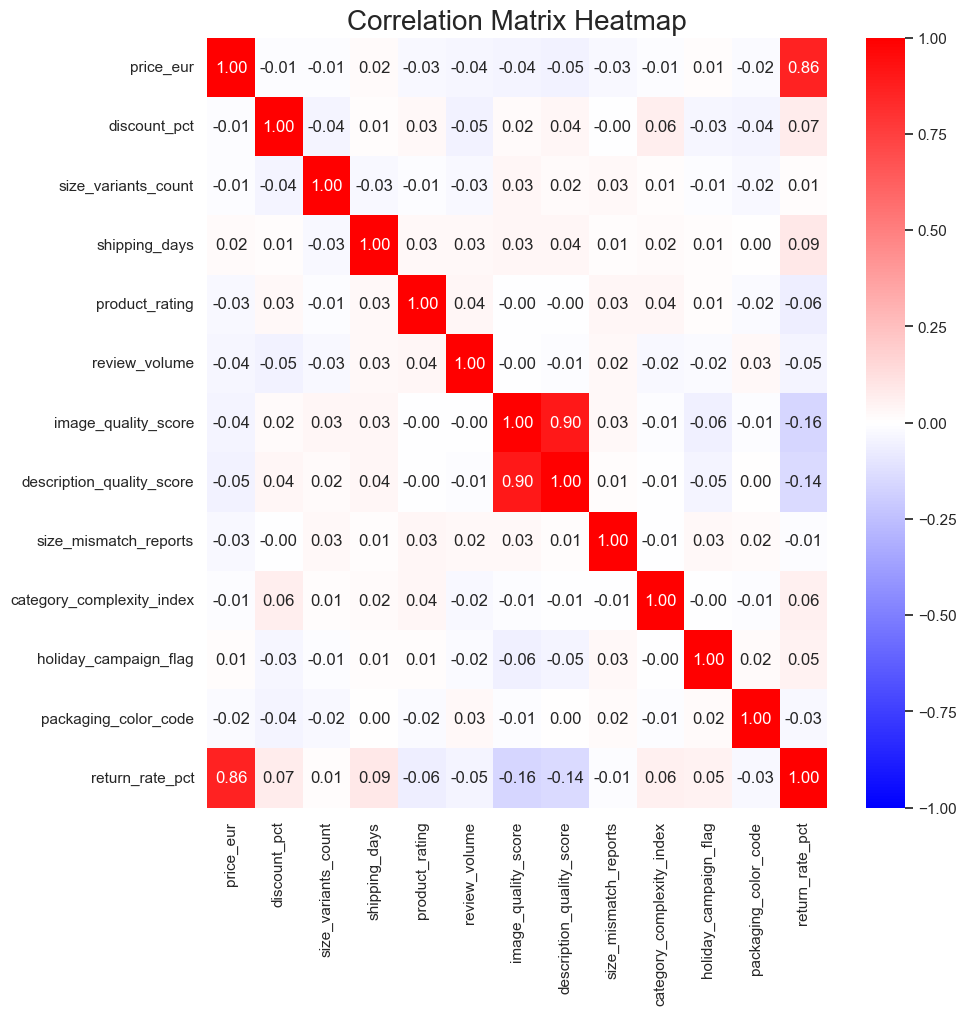

In [5]:
fig = plt.figure(figsize=(10,10))
plt.title("Correlation Matrix Heatmap", fontsize=20)
sns.heatmap(train.corr(), cmap="bwr", vmin ='-1', annot=True, fmt=".2f")
plt.show()

After an initial inspection of the heatmap, we can already observe:
- `price_eur` is **highly positively correlated** (0.86) with our target, which is `return_rate_pct` (more expensive products seem to be more likely to be returned)
- `image_quality_score` and `description_quality_score` are **negatively correlated** (-0.16, -0.14) with our target (products with lower quality presentation are more likely to be returned); at the same time, they are **highly positively correlated** with each other (0.9)
- excluding `image_quality_score` and `description_quality_score`, there doesn't seem to exist strong multicollinearity between the features themselves
- `discount_pct`, `shopping_days`, `cateogry_complexity_index`, `holiday_campaign_flag`, `review_volume`, `product_raiting` are not very highly correlated ($0.05 < |\cdot| < 0.09$) with the target, but as their names suggest, could still be reasonably relevant for the prediction (for example, we expect product raitings to somewhat affect the return rate)
- `size_variants_count`, `size_mismatch_reports` and `packaging_color_code` only show little correlation with the target 


## Distributions of features and target

## Target distribution is bimodal

First, it is important to analyze the distribution of the target (`return_rate_pct`):

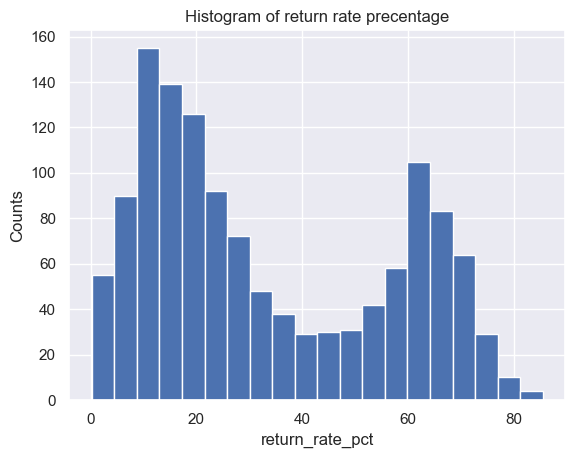

In [18]:
fig = plt.figure()
plt.title("Histogram of return rate precentage")
plt.ylabel("Counts")
plt.xlabel("return_rate_pct")
plt.hist(train['return_rate_pct'], bins=20)
plt.show()

It is a bimodal distribution with one peak around the 10-15% return rate and another around the 60-65% return rate. 

Our dataset doesn't seem to include a lot of entries in the middleground, so most campaigns either have a reasonbly low return rate, or a reasonbly high return rate, and the respective rates are approximately "normally distributed" with respect to the peaks.

This particular shape could be problematic in obtaining accurate predictions, so we will need to mitigate this issue when we start applying models.

## The bimodal distribution of the target reflected in relation to the features

When attempting to plot the features (except for `price_eur`) against `return_rate_pct` we observe a similar bimodal pattern.

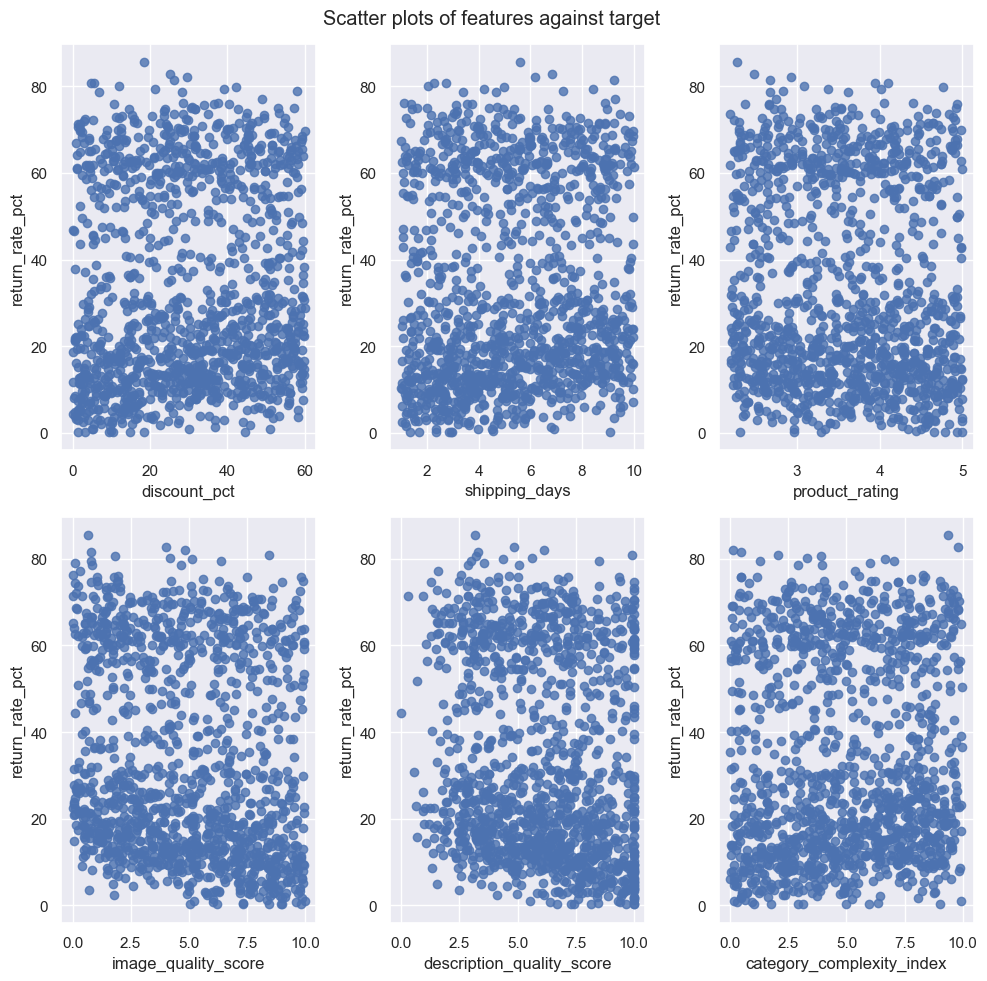

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(10,10))
plt.suptitle("Scatter plots of features against target")

# Plot each of the selected features against the target
features = ['discount_pct', 'shipping_days', 'product_rating', 'image_quality_score', 'description_quality_score', 'category_complexity_index']
for i, ax in enumerate(axes.flat):
    ax.scatter(train[features[i]], train['return_rate_pct'], alpha=0.8)
    ax.set_xlabel(features[i])
    ax.set_ylabel('return_rate_pct')

plt.tight_layout()
plt.show()

- The middle region in each feature vs target scatterplot is caused by the existence of the two modes of the distribution of `return_rate_pct`. 
- Beyond this, the relationships between those features and the target are not perfectly clear; this is expected given the low correlation coefficients between most of the featuers and target. 

## `price_eur` against the target 

Perhaps the most important predictor for our target is the `price_eur`, with a huge correlation coefficient of 0.86.

Let us vizualise their relationship:

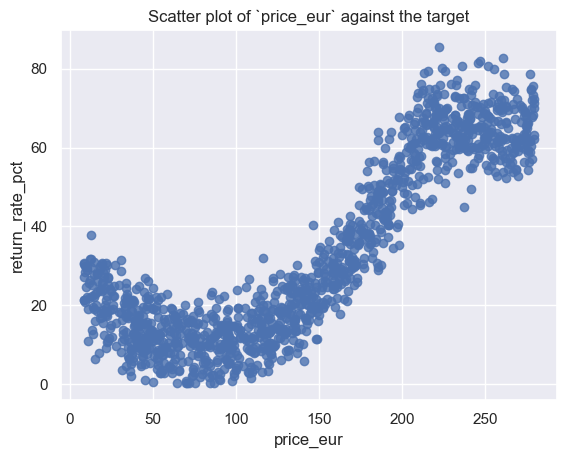

In [36]:
fig = plt.figure()
plt.title("Scatter plot of `price_eur` against the target")
plt.ylabel("return_rate_pct")
plt.xlabel("price_eur")
plt.scatter(train['price_eur'], train['return_rate_pct'], alpha=0.8)
plt.show()

The pattern resembles a polynomial of degree greater than 2 (we will look more into the exact degree later). This is promising for our model, as until this point, it is the clearest link between a feature and the target.

## The linear relationship between `image_quality_score` and `description_quality_score`

Pearson Correlation Coefficient: 0.90


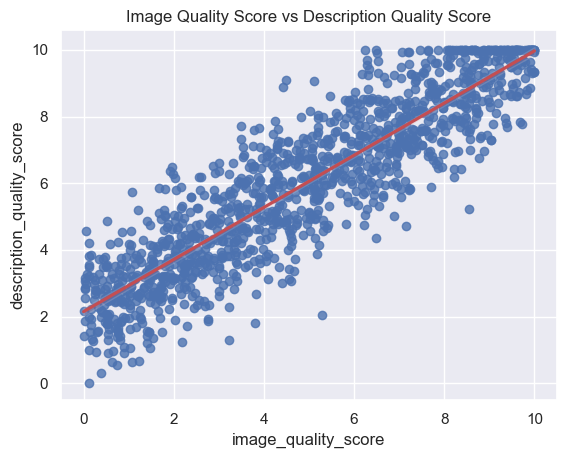

In [40]:
# Calculate the Pearson correlation coefficient
corr_coef = train['image_quality_score'].corr(train['description_quality_score'])
print(f"Pearson Correlation Coefficient: {corr_coef:.2f}")

# Plot the relationship
fig = plt.figure()
plt.title("Image Quality Score vs Description Quality Score")
sns.regplot(data=train, x='image_quality_score', y='description_quality_score', line_kws=dict(color="r"))
plt.show()

There is clearly a linear relationship between the `image_quality_score` and `description_quality_score` features, with a **Pearson Correlation Coefficient** of **0.90**.

# Models for making predictions